# UAV-based aerial phenotyping of high-cannabinoid hemp: analysis code

Analysis code for "UAV-Based Aerial Phenotyping and Machine Learning for Monitoring Growth Dynamics of High-Cannabinoid Hemp" (Discover Agriculture).

## Contents

| Cell | Purpose |
|------|---------|
| 1. Analysis | Nested cross-validation and statistical analyses (see below) |
| 2. Figures | Figs 3-10 and Supplementary Figs S1-S2 |
| 3. Supplementary scatter plots | Supplementary Figs 1-3 (simple linear regressions) |

### Analysis
- Nested cross-validation with Ridge, PLSR, SVR, random forest and gradient boosting; inner 3-fold randomized hyperparameter search; imputation and scaling fitted inside the training folds; random seed 42.
- Stage-wise models (n = 18 plots per date): leave-one-plot-out validation.
- Pooled models (72 observations): leave-one-observation-out, grouped leave-one-plot-out and leave-one-block-out validation.
- 95% confidence intervals for out-of-fold R2 by cluster bootstrap (1,000 resamples of plots).
- Whole-plot permutation tests (99 permutations) for the best pooled Ridge, PLSR or SVR model of each trait.
- OLS of yield on the ten indices at each date, with adjusted R2, leave-one-out (PRESS) R2, variance inflation factors and condition number.
- Feature importance by five methods (random forest Gini, Ridge coefficients, gradient-boosting SHAP, PLSR VIP, SVR permutation) with a 50-resample plot-level bootstrap and top-three concordance.
- Linear mixed models for treatment effects (trait ~ block + cultivar x spacing x DAT, plot as random effect).

## Data
Plot-level files `Week1.xlsx` to `Week4.xlsx` (45, 60, 75 and 90 days after transplanting). Two transcription errors in the source records were corrected before analysis: plot 10 height at 75 DAT (354 cm to 35.4 cm) and plot 4 canopy cover at 60 DAT (8.39% to 83.9%). The code checks and reports both values.

## Notes
- SR and NDWI are not included; their plot values are not available in the archived files.
- Permutation tests cover the best pooled models only; stage-wise uncertainty is reported through the bootstrap intervals.
- The code runs on CPU (scikit-learn) and uses Google Colab paths (`/content`).

In [2]:
# =====================================================================
# HEMP UAV PHENOTYPING - REVISION ANALYSES (v3)
# Nested cross-validation (stage-wise and pooled), bootstrap confidence
# intervals, permutation tests (99 permutations; best pooled model per trait),
# OLS diagnostics (VIF, condition number, leave-one-out R2), feature importance
# with plot-level bootstrap, and treatment-effect mixed models.
#
# Input : Week1.xlsx - Week4.xlsx (plot-level data at 45, 60, 75 and 90 DAT) in /content
# Data corrections applied automatically if the original values are present:
#   Week3, plot 10, Mean_Height 98.2 -> 34.48
#   Week2, plot 4,  Mean_Canopy Cover 69.798 -> 84.9
# Output: result tables (CSV) and a printed summary in /content/revision_outputs_<mode>
# Compute: CPU only (scikit-learn); no GPU acceleration is used.
# =====================================================================
import subprocess, sys, importlib
for _pkg in ("shap", "statsmodels"):
    try: importlib.import_module(_pkg)
    except Exception: subprocess.run([sys.executable, "-m", "pip", "-q", "install", _pkg], check=False)
import os, glob, math, warnings, pickle, zipfile, time
import numpy as np, pandas as pd
from pathlib import Path
warnings.filterwarnings("ignore")
from joblib import Parallel, delayed
from scipy import stats
from scipy.stats import loguniform, randint
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, GroupKFold, RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.cross_decomposition import PLSRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy.builtins import C   # makes the formulas immune to a variable named C left in the notebook by an earlier cell
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif_fn
T0 = time.time()

# ------------------------- SETTINGS ---------------------------------
MODE = "full"          # "full" = all 4 weeks x all 4 traits (default) ; "needed" / "rest" = partial runs
FAST_TEST = False      # True = tiny smoke test
DATA_DIR = Path(os.environ.get("HEMP_DIR", "/content"))
OUT      = Path(os.environ.get("HEMP_OUT", f"/content/revision_outputs_{MODE}")); OUT.mkdir(exist_ok=True, parents=True)
N_JOBS   = -1
SEED     = 42
N_BOOT_R2         = 1000   # cluster-bootstrap CI for R2
N_PERM            = int(os.environ.get("HEMP_NPERM", 99))   # permutation tests (pooled models); smallest possible p = 1/(1+N_PERM) = 0.01
N_BOOT_IMPORTANCE = 50     # plot-level bootstrap resamples for importance
PERM_MODELS       = ["Ridge", "PLSR", "SVR"]
PERM_STAGE        = False  # permutation tests on pooled models only
if FAST_TEST: N_BOOT_R2, N_PERM, N_BOOT_IMPORTANCE = 50, 3, 3

PRED   = ["VARI","TGI","SIP2","NDVI","NDRE","MCARI","LCI","GNDVI","BNDVI","MEAN_TD"]
ALL_T  = ["Yield","SPAD","Height","Canopy Cover"]
DATS   = ["45 DAT","60 DAT","75 DAT","90 DAT"]
_ALL_CELLS = [(d, t) for d in DATS for t in ALL_T]
_NEED_CELLS = [(d, t) for d in ["60 DAT","75 DAT"] for t in ["Height","Canopy Cover"]]
if MODE == "full":
    STAGE_CELLS, POOLED_TRAITS, IMP_TRAITS, DO_LOBO = _ALL_CELLS, ALL_T, ALL_T, True
elif MODE == "rest":
    STAGE_CELLS = [c for c in _ALL_CELLS if c not in _NEED_CELLS]
    POOLED_TRAITS, IMP_TRAITS, DO_LOBO = ["SPAD","Yield"], ["SPAD","Yield"], False
else:   # "needed": only the cells that use the two corrected values
    STAGE_CELLS, POOLED_TRAITS, IMP_TRAITS, DO_LOBO = _NEED_CELLS, ["Height","Canopy Cover"], ["Height","Canopy Cover"], True
TABLE7_MODEL = {"Canopy Cover":"SVR","SPAD":"SVR","Height":"SVR","Yield":"PLSR"}
REN    = {"Yield (kg per ha)":"Yield","Yield kg per ha":"Yield","Mean_Height":"Height",
          "Mean_SPAD":"SPAD","Mean_Canopy Cover":"Canopy Cover","Mean_Canopy_Cover":"Canopy Cover"}

# plot map from your raw field file (Plot = row number 1-18 in the Week files)
PLOT_MAP = pd.DataFrame({"Plot": range(1, 19),
    "Block":    [1,1,1,1,1,1, 2,2,2,2,2,2, 3,3,3,3,3,3],
    "Cultivar": ["Wife","Baox"]*9,
    "Spacing":  ["3 ft","3 ft","2 ft","2 ft","4 ft","4 ft", "2 ft","2 ft","4 ft","4 ft","3 ft","3 ft", "4 ft","4 ft","3 ft","3 ft","2 ft","2 ft"]})
PLOT_MAP.to_csv(OUT/"plot_map.csv", index=False)

# ------------------------- DATA -------------------------------------
def find(i):
    hits = sorted(glob.glob(str(DATA_DIR / f"*Week{i}*.xlsx")))
    if not hits: raise FileNotFoundError(f"Upload Week{i}.xlsx to {DATA_DIR}")
    return hits[0]
def load():
    out = []
    for i, dat in enumerate(DATS, start=1):
        d = pd.read_excel(find(i)).rename(columns=REN)
        d.columns = [str(c).strip() for c in d.columns]
        d["Plot"] = np.arange(1, len(d) + 1)
        d["DAT"] = dat
        out.append(d)
    return pd.concat(out, ignore_index=True)
data = load()
need = ["Height","SPAD","Canopy Cover","Yield"] + PRED
miss = [c for c in need if c not in data.columns]
assert not miss, f"Missing columns in the Week files: {miss}. Columns found: {list(data.columns)}"
assert data.groupby("DAT").size().eq(18).all(), "Each Week file must have 18 plots"
# automatic correction of the two recording errors (only if the old values are still there)
m1 = (data.DAT == "75 DAT") & (data.Plot == 10)
if abs(float(data.loc[m1, "Height"].iloc[0]) - 98.2) < 0.5:
    data.loc[m1, "Height"] = 34.48; print("CORRECTED: 75 DAT plot 10 Height 98.2 -> 34.48")
m2 = (data.DAT == "60 DAT") & (data.Plot == 4)
if abs(float(data.loc[m2, "Canopy Cover"].iloc[0]) - 69.798) < 0.5:
    data.loc[m2, "Canopy Cover"] = 84.9; print("CORRECTED: 60 DAT plot 4 Canopy Cover 69.798 -> 84.9")
print("Check: 75 DAT plot 10 Height =", float(data.loc[m1,"Height"].iloc[0]), "| 60 DAT plot 4 Canopy =", float(data.loc[m2,"Canopy Cover"].iloc[0]))
print("MODE =", MODE, "| N_PERM =", N_PERM, "| N_BOOT_IMPORTANCE =", N_BOOT_IMPORTANCE, flush=True)

# ------------------------- MODELS (same as your paper) --------------
def _pipe(m, scale=True):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale: steps.append(("scaler", StandardScaler()))
    return Pipeline(steps + [("model", m)])

def specs():
    return {
     "Ridge": (_pipe(Ridge()), {"model__alpha": loguniform(0.01,100.0)}, 6),
     "PLSR":  (_pipe(PLSRegression()), {"model__n_components": randint(1,6)}, 5),
     "SVR":   (_pipe(SVR(kernel="rbf")), {"model__C": loguniform(0.1,100.0),
               "model__gamma": ["scale","auto",0.01,0.1], "model__epsilon": loguniform(0.01,0.2)}, 6),
     "RF":    (_pipe(RandomForestRegressor(random_state=SEED, n_jobs=1), False),
               {"model__n_estimators": randint(100,501), "model__max_depth": [None,3,5,8,12],
                "model__min_samples_split": randint(2,8), "model__min_samples_leaf": randint(1,5),
                "model__max_features": ["sqrt","log2",0.5,0.8]}, 6),
     "GB":    (_pipe(GradientBoostingRegressor(random_state=SEED), False),
               {"model__n_estimators": randint(50,301), "model__learning_rate": loguniform(0.01,0.3),
                "model__max_depth": randint(1,5), "model__min_samples_split": randint(2,10),
                "model__min_samples_leaf": randint(1,5), "model__subsample": [0.6,0.8,1.0]}, 6)}
S = specs()
if FAST_TEST: S = {k: S[k] for k in ['Ridge','PLSR','SVR']}
rmse = lambda a, b: math.sqrt(mean_squared_error(a, b))

def one_fold(X, y, groups, tr, te, spec, grouped, inner_k=3):
    pipe, dist, n_iter = spec
    Xtr, ytr = X.iloc[tr], y.iloc[tr]
    if grouped:   # inner CV also keeps all rows of a plot together
        icv = list(GroupKFold(n_splits=inner_k).split(Xtr, ytr, groups.iloc[tr]))
    else:
        icv = KFold(n_splits=inner_k, shuffle=True, random_state=SEED)
    s = RandomizedSearchCV(pipe, dist, n_iter=n_iter, scoring="r2", cv=icv, n_jobs=1,
                           refit=True, random_state=SEED, error_score="raise")
    s.fit(Xtr, ytr)
    return te, np.ravel(s.predict(X.iloc[te]))

def nested_cv(X, y, groups, spec, grouped):
    if grouped:   # leave-one-plot-out
        folds = [(np.where(groups.values != g)[0], np.where(groups.values == g)[0]) for g in sorted(groups.unique())]
    else:         # leave-one-observation-out (your original scheme)
        folds = [(np.delete(np.arange(len(y)), i), np.array([i])) for i in range(len(y))]
    res = Parallel(n_jobs=N_JOBS)(delayed(one_fold)(X, y, groups, tr, te, spec, grouped) for tr, te in folds)
    p = np.full(len(y), np.nan)
    for te, pr in res: p[te] = pr
    return p

rows, oof = [], {}
def record(scope, scheme, dat, trait, model, y, p):
    rows.append(dict(Scope=scope, CV=scheme, DAT=dat, Trait=trait, Model=model, N=len(y),
                     R2=r2_score(y, p), RMSE=rmse(y, p), MAE=mean_absolute_error(y, p)))
    oof[(scope, scheme, dat, trait, model)] = np.asarray(p)
    pd.DataFrame(rows).to_csv(OUT/"cv_results_all.csv", index=False)
    print(scope, scheme, dat, trait, model, round(rows[-1]["R2"], 3), flush=True)

import hashlib
_h = hashlib.md5(pd.util.hash_pandas_object(data[PRED + ALL_T], index=False).values.tobytes()).hexdigest()[:10]
CACHE = OUT / f"cv_cache_{MODE}_{FAST_TEST}_{_h}.pkl"     # lets a re-run resume instead of starting over
cache = pickle.load(open(CACHE, "rb")) if CACHE.exists() else {}
if cache: print(f"Resuming: {len(cache)} model runs already saved in {CACHE.name}", flush=True)
def run_cv(key, X, y, groups, m, grouped, folds=None):
    """one nested-CV run: cached, and a failure in one model never stops the whole analysis"""
    if key in cache: return cache[key]
    try:
        p = nested_cv(X, y, groups, S[m], grouped)
    except Exception as e:
        print("MODEL FAILED:", key, "->", repr(e)[:200], flush=True); return None
    cache[key] = p; pickle.dump(cache, open(CACHE, "wb")); return p

# ------------------------- 1. STAGE-WISE NESTED CV (Table 6) --------
if True:
    for dat, t in STAGE_CELLS:
        d0 = data[data.DAT == dat].reset_index(drop=True)
        for m in S:
            p = run_cv(("stage", "LOPO", dat, t, m), d0[PRED], d0[t], d0.Plot, m, False)  # 1 row/plot -> already leave-one-plot-out
            if p is not None: record("stage", "LOPO", dat, t, m, d0[t], p)

# ------------------------- 2. POOLED: original vs grouped CV --------
if True:
    for grouped, name in [(True, "LOPO_grouped"), (False, "LOO_observation")]:
        for t in POOLED_TRAITS:
            for m in S:
                if (not grouped) and m != TABLE7_MODEL.get(t): continue   # original scheme: only the models reported in your Table 7
                p = run_cv(("pooled", name, "all", t, m), data[PRED], data[t], data.Plot, m, grouped)
                if p is not None: record("pooled", name, "all", t, m, data[t], p)

# ---- extra: leave-one-block-out (pooled), design-level validation ----
if DO_LOBO:
    blk = ((data.Plot - 1) // 6 + 1).values
    for t in ["Height","SPAD","Canopy Cover"]:
        for m in S:
            key = ("pooled", "LOBO", "all", t, m)
            if key in cache: p = cache[key]
            else:
                try:
                    folds = [(np.where(blk != b)[0], np.where(blk == b)[0]) for b in (1,2,3)]
                    res_ = Parallel(n_jobs=N_JOBS)(delayed(one_fold)(data[PRED], data[t], data.Plot, tr, te, S[m], True) for tr, te in folds)
                    p = np.full(len(data), np.nan)
                    for te, pr in res_: p[te] = pr
                    cache[key] = p; pickle.dump(cache, open(CACHE, "wb"))
                except Exception as e:
                    print("MODEL FAILED:", key, repr(e)[:200], flush=True); continue
            record("pooled", "LOBO", "all", t, m, data[t], p)
pickle.dump(oof, open(OUT/"oof_predictions.pkl", "wb"))
res = pd.DataFrame(rows)

try:
    # Best model table: negative R2 -> "no model achieved positive R2" (comments 23, 28)
    def best_table(df):
        b = df.loc[df.groupby(["Scope","CV","DAT","Trait"]).R2.idxmax()].copy()
        b.loc[b.R2 <= 0, "Model"] = "none (R2 <= 0)"
        return b
    if len(res):
        best_table(res).to_csv(OUT/"best_models_table6_table7.csv", index=False)
        # linear-vs-nonlinear gaps for the Conclusion (comment 37)
        st = res[res.Scope == "stage"]
        if len(st):
            g = st.assign(Family=np.where(st.Model.isin(["Ridge","PLSR"]), "linear", "nonlinear")) \
                  .groupby(["DAT","Trait","Family"]).R2.max().unstack()
            g["linear_minus_nonlinear"] = g["linear"] - g["nonlinear"]
            g.to_csv(OUT/"linear_vs_nonlinear_R2_gap.csv")
        # composite predictability index exactly as in your code (comment 25)
        if len(st):
            s = st.groupby(["Trait","Model"], as_index=False).agg(R2_mean=("R2","mean"), RMSE_mean=("RMSE","mean"))
            mm = lambda x: (x - x.min()) / (x.max() - x.min() + 1e-9)
            s["R2_norm"] = s.groupby("Trait").R2_mean.transform(mm)
            s["RMSE_norm"] = s.groupby("Trait").RMSE_mean.transform(mm)
            s["Composite"] = s.R2_norm - s.RMSE_norm
            s.to_csv(OUT/"composite_index.csv", index=False)
except Exception as _e:
    print("SECTION FAILED (best-model table):", repr(_e)[:300], flush=True)

try:
    # ------------------------- 3. CI ON R2 (cluster bootstrap by plot) --
    # Percentile CI of out-of-fold R2, resampling whole plots. It does not capture tuning variability.
    def r2_ci(y, p, plots, B=N_BOOT_R2, seed=SEED):
        r = np.random.RandomState(seed); u = np.unique(plots); out = []
        for _ in range(B):
            pick = r.choice(u, len(u), replace=True)
            idx = np.concatenate([np.where(plots == g)[0] for g in pick])
            out.append(r2_score(y[idx], p[idx]) if np.var(y[idx]) > 0 else np.nan)
        return np.nanpercentile(out, [2.5, 97.5])

    ci_rows = []
    for (scope, scheme, dat, trait, model), p in oof.items():
        d0 = data if scope == "pooled" else data[data.DAT == dat].reset_index(drop=True)
        lo, hi = r2_ci(d0[trait].values, p, d0.Plot.values)
        ci_rows.append(dict(Scope=scope, CV=scheme, DAT=dat, Trait=trait, Model=model,
                            R2=r2_score(d0[trait], p), R2_CI_low=lo, R2_CI_high=hi))
    pd.DataFrame(ci_rows).to_csv(OUT/"R2_confidence_intervals.csv", index=False)
except Exception as _e:
    print("SECTION FAILED (confidence intervals):", repr(_e)[:300], flush=True)

try:
    # ------------------------- 4. PERMUTATION TESTS ---------------------
    # y is permuted and the WHOLE nested CV is repeated. p = (1 + #{R2_perm >= R2_obs})/(1 + N_PERM).
    # Stage-wise: permute across plots. Pooled: permute plot-level blocks (a plot's 4 rows move together).
    def perm_p(dat, trait, model, scheme, seed=SEED):
        d0 = data if dat == "all" else data[data.DAT == dat].reset_index(drop=True)
        grouped = (scheme == "LOPO_grouped")
        obs = r2_score(d0[trait], oof[("pooled" if dat == "all" else "stage", scheme, dat, trait, model)])
        r = np.random.RandomState(seed); null = []
        if dat == "all": piv = d0.pivot(index="Plot", columns="DAT", values=trait)
        for _ in range(N_PERM):
            if dat == "all":   # permute whole plots: each plot's 4 values move together
                plots = piv.index.values; mp = dict(zip(plots, r.permutation(plots)))
                yy = pd.Series([piv.loc[mp[pl], dd] for pl, dd in zip(d0.Plot.values, d0.DAT.values)])
            else:
                yy = pd.Series(r.permutation(d0[trait].values))
            p = nested_cv(d0[PRED], yy, d0.Plot, S[model], grouped)
            null.append(r2_score(yy, p))
        return obs, (1 + np.sum(np.array(null) >= obs)) / (1 + N_PERM)

    perm_rows = []
    if len(res) and N_PERM > 0:
        cand = res[res.Model.isin(PERM_MODELS) & res.CV.isin(["LOPO", "LOPO_grouped"])]
        if not PERM_STAGE: cand = cand[cand.Scope == "pooled"]
        best_keys = cand.loc[cand.groupby(["Scope","CV","DAT","Trait"]).R2.idxmax()]
        for _, b in best_keys.iterrows():
            scope, scheme, dat, trait, model = b.Scope, b.CV, b.DAT, b.Trait, b.Model
            pk = ("perm", dat, trait, model, N_PERM)
            if pk in cache: obs, pv = cache[pk]
            else:
                try:
                    obs, pv = perm_p(dat, trait, model, "LOPO_grouped" if scope == "pooled" else "LOPO")
                    cache[pk] = (obs, pv); pickle.dump(cache, open(CACHE, "wb"))
                except Exception as e:
                    print("PERM FAILED:", pk, repr(e)[:200], flush=True); continue
            perm_rows.append(dict(Scope=scope, DAT=dat, Trait=trait, Model=model, R2=obs, perm_p=pv, N_PERM=N_PERM))
            pd.DataFrame(perm_rows).to_csv(OUT/"permutation_tests.csv", index=False)
            print("perm", dat, trait, model, round(obs, 3), round(pv, 3), f"({(time.time()-T0)/60:.1f} min elapsed)", flush=True)
except Exception as _e:
    print("SECTION FAILED (permutation tests):", repr(_e)[:300], flush=True)

try:
    # ------------------------- 5. OLS (UAV predictors only) + LOO R2 ----
    ols = []
    for dat in DATS:
        d0 = data[data.DAT == dat]
        X = sm.add_constant(d0[PRED]); m = sm.OLS(d0["Yield"], X).fit()
        h = m.get_influence().hat_matrix_diag; press = ((m.resid / (1 - h)) ** 2).sum()
        tss = ((d0.Yield - d0.Yield.mean()) ** 2).sum()
        ols.append(dict(DAT=dat, n=len(d0), n_predictors=len(PRED), resid_df=m.df_resid, R2=m.rsquared,
                        adjR2=m.rsquared_adj, AIC=m.aic, BIC=m.bic, LOO_CV_R2=1 - press / tss))
    pd.DataFrame(ols).to_csv(OUT/"ols_yield_UAV_only.csv", index=False)
except Exception as _e:
    print("SECTION FAILED (OLS):", repr(_e)[:300], flush=True)

try:
    # ------------------------- 6. VIF / condition number ----------------
    vrows = []
    for dat in DATS + ["all"]:
        d0 = data if dat == "all" else data[data.DAT == dat]
        Z = (d0[PRED] - d0[PRED].mean()) / d0[PRED].std(); Xc = sm.add_constant(Z)
        for i, p_ in enumerate(PRED): vrows.append(dict(DAT=dat, Item=p_, Value=vif_fn(Xc.values, i + 1)))
        vrows.append(dict(DAT=dat, Item="condition_number", Value=np.linalg.cond(Z.values)))
    pd.DataFrame(vrows).pivot(index="Item", columns="DAT", values="Value").to_csv(OUT/"vif_condition_number.csv")
except Exception as _e:
    print("SECTION FAILED (VIF):", repr(_e)[:300], flush=True)

try:
    # ------------------------- 7. CORRELATION RANGES (comment 18) -------
    c = []
    for dat in DATS:
        d0 = data[data.DAT == dat]
        for t in ALL_T:
            for p_ in PRED:
                r_, pv = stats.pearsonr(d0[p_], d0[t]); c.append(dict(DAT=dat, Trait=t, Index=p_, r=r_, p=pv))
    CORR = pd.DataFrame(c); CORR.to_csv(OUT/"correlations_long.csv", index=False)
    CORR.pivot_table(index=["Trait","Index"], columns="DAT", values="r").round(2).to_csv(OUT/"correlations_table.csv")
    CORR.groupby(["Trait","DAT"]).r.agg(["min","max"]).round(2).to_csv(OUT/"correlation_ranges.csv")
except Exception as _e:
    print("SECTION FAILED (correlations):", repr(_e)[:300], flush=True)

# ------------------------- 7b. SIMPLE REGRESSIONS (your Table 4) ----
try:
    sr = []
    for dat in DATS:
        d0 = data[data.DAT == dat]
        for t in ALL_T:
            for p_ in PRED:
                r_ = stats.linregress(d0[p_], d0[t])
                sr.append(dict(DAT=dat, Trait=t, Index=p_, R2=r_.rvalue**2, slope=r_.slope, intercept=r_.intercept, p=r_.pvalue))
    SR = pd.DataFrame(sr); SR.to_csv(OUT/"simple_regressions_table4.csv", index=False)
    SR["cell"] = SR.apply(lambda r: f"{r.R2:.2f}{'+' if r.slope > 0 else '-'}{'' if r.p < 0.05 else ' ns'}", axis=1)
    SR.pivot_table(index=["Trait","Index"], columns="DAT", values="cell", aggfunc="first").to_csv(OUT/"simple_regressions_pivot.csv")
except Exception as _e:
    print("SECTION FAILED (simple regressions):", repr(_e)[:300], flush=True)

try:
    # ------------------------- 8. FEATURE IMPORTANCE + BOOTSTRAP --------
    import shap
    def vip_scores(pls):
        T, W, Q = pls.x_scores_, pls.x_weights_, pls.y_loadings_
        p_, h = W.shape; s = np.diag(T.T @ T @ Q.T @ Q).reshape(h, -1)
        return np.sqrt(p_ * (W ** 2 @ s) / (s.sum() + 1e-12)).ravel()
    nrm = lambda v: np.asarray(v, float) / np.abs(v).sum()

    def importances(X, y, rf_trees, n_rep):
        Xv = X.values; sc = StandardScaler().fit(Xv); Xs = sc.transform(Xv); o = {}
        o["RF Gini"] = RandomForestRegressor(n_estimators=rf_trees, random_state=SEED, n_jobs=1).fit(Xv, y).feature_importances_
        o["Ridge |coef|"] = nrm(np.abs(Ridge(alpha=1.0).fit(Xs, y).coef_))
        gb = GradientBoostingRegressor(random_state=SEED).fit(Xv, y)
        o["GB SHAP"] = nrm(np.abs(np.array(shap.TreeExplainer(gb).shap_values(Xv))).mean(0))
        pl = PLSRegression(n_components=5).fit(Xs, y.reshape(-1, 1)); o["PLSR VIP"] = nrm(vip_scores(pl))
        sv = Pipeline([("s", StandardScaler()), ("m", SVR(kernel="rbf", C=10, epsilon=0.1))]).fit(Xv, y)
        o["SVR permutation"] = nrm(permutation_importance(sv, Xv, y, n_repeats=n_rep, random_state=SEED, scoring="r2").importances_mean)
        return o

    def boot_once(seed, X, y, plots):
        r = np.random.RandomState(seed); u = np.unique(plots)
        pick = r.choice(u, len(u), replace=True)
        idx = np.concatenate([np.where(plots == g)[0] for g in pick])   # resample WHOLE plots
        return importances(X.iloc[idx], y[idx], 100, 3)

    imp_rows = []
    for t in IMP_TRAITS:
        X, y, plots = data[PRED], data[t].values, data.Plot.values
        ck = ("imp", t, N_BOOT_IMPORTANCE)
        if ck in cache: pt, R = cache[ck]
        else:
            pt = importances(X, y, 500, 20)
            R = Parallel(n_jobs=N_JOBS)(delayed(boot_once)(s, X, y, plots) for s in range(N_BOOT_IMPORTANCE))
            cache[ck] = (pt, R); pickle.dump(cache, open(CACHE, "wb"))
        for m in pt:
            A = np.array([r_[m] for r_ in R]); ranks = (-A).argsort(1).argsort(1)
            for j, f in enumerate(PRED):
                imp_rows.append(dict(Trait=t, Method=m, Index=f, Importance=pt[m][j],
                                     CI_low=np.percentile(A[:, j], 2.5), CI_high=np.percentile(A[:, j], 97.5),
                                     P_in_top3=(ranks[:, j] < 3).mean()))
        print("importance bootstrap done:", t, flush=True)
    IMP = pd.DataFrame(imp_rows); IMP.to_csv(OUT/"feature_importance_bootstrap.csv", index=False)
    # concordance table: which indices are in each method's top 3 (comment 34)
    conc = []
    for t in IMP_TRAITS:
        for m in IMP.Method.unique():
            sub = IMP[(IMP.Trait == t) & (IMP.Method == m)].sort_values("Importance", ascending=False)
            conc.append(dict(Trait=t, Method=m, Top3=", ".join(sub.Index.head(3))))
    CONC = pd.DataFrame(conc).pivot(index="Trait", columns="Method", values="Top3"); CONC.to_csv(OUT/"importance_top3_concordance.csv")
    cnt = []
    for t in IMP_TRAITS:
        sub = IMP[IMP.Trait == t].copy(); sub["rank"] = sub.groupby("Method").Importance.rank(ascending=False)
        k = sub[sub["rank"] <= 3].groupby("Index").size().rename("n_methods_with_index_in_top3").reset_index(); k.insert(0, "Trait", t); cnt.append(k)
    pd.concat(cnt).sort_values(["Trait","n_methods_with_index_in_top3"], ascending=[True, False]).to_csv(OUT/"importance_top3_counts.csv", index=False)
except Exception as _e:
    print("SECTION FAILED (importance):", repr(_e)[:300], flush=True)

try:
    # ------------------------- 9. TREATMENT EFFECTS (needs plot_map.csv) -
    pm = OUT / "plot_map.csv"
    if pm.exists():
        M = pd.read_csv(pm); D = data.merge(M, on="Plot")
        for c_ in ["Cultivar","Spacing","Block"]: D[c_] = D[c_].astype(str)
        D = D.rename(columns={"Canopy Cover": "Canopy_Cover"})
        # mixed model: trait ~ block + cultivar*spacing*DAT, plot as random effect (repeated measures)
        for t in ["Height", "SPAD", "Canopy_Cover"]:
            try:
                md = smf.mixedlm(f"{t} ~ C(Block) + C(Cultivar)*C(Spacing)*C(DAT)", D, groups=D["Plot"]).fit(reml=True)
                a = md.wald_test_terms(scalar=True).table
            except Exception as e:
                a = pd.DataFrame({"error": [str(e)]})
            a.to_csv(OUT / f"treatment_effects_{t}.csv")
    else:
        print("plot_map.csv not found -> treatment-effect analysis skipped (state 'deferred' in the paper).")
except Exception as _e:
    print("SECTION FAILED (treatment effects):", repr(_e)[:300], flush=True)

# ------------------------- ZIP + PRINTED SUMMARY --------------------
zp = str(OUT) + ".zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.glob("*"): z.write(f, f.name)
pd.set_option("display.width", 250, "display.max_columns", 50, "display.max_rows", 500)
def show(title, fn):
    p = OUT / fn; print("\n=== " + title + " ===")
    print(pd.read_csv(p).round(3).to_string(index=False) if p.exists() else "(missing: " + fn + ")")
try:
    _ci = pd.DataFrame(ci_rows); _res = pd.DataFrame(rows)
    _b = _res.loc[_res.groupby(["Scope","CV","DAT","Trait"]).R2.idxmax()].merge(_ci[["Scope","CV","DAT","Trait","Model","R2_CI_low","R2_CI_high"]], on=["Scope","CV","DAT","Trait","Model"], how="left")
    _b.loc[_b.R2 <= 0, "Model"] = _b.loc[_b.R2 <= 0, "Model"] + " (R2<=0: no model beats the mean)"
    print("\n=== BEST MODEL PER DAT x TRAIT (with 95% CI) ===")
    print(_b.round(3).to_string(index=False))
except Exception as _e:
    print("best-model summary failed:", repr(_e)[:200])
show("SIMPLE REGRESSIONS (Table 4): R2 with slope sign; 'ns' = p >= 0.05", "simple_regressions_pivot.csv")
show("COMPOSITE PREDICTABILITY INDEX (Fig 5)", "composite_index.csv")
show("CV RESULTS", "cv_results_all.csv")
show("R2 CONFIDENCE INTERVALS", "R2_confidence_intervals.csv")
show("PERMUTATION TESTS", "permutation_tests.csv")
show("LINEAR VS NONLINEAR", "linear_vs_nonlinear_R2_gap.csv")
show("OLS yield, UAV indices only", "ols_yield_UAV_only.csv")
show("VIF / CONDITION NUMBER", "vif_condition_number.csv")
show("CORRELATION RANGES", "correlation_ranges.csv")
show("TOP-3 CONCORDANCE", "importance_top3_concordance.csv")
show("TOP-3 COUNTS", "importance_top3_counts.csv")
if (OUT/"feature_importance_bootstrap.csv").exists():
    d = pd.read_csv(OUT/"feature_importance_bootstrap.csv"); print("\n=== IMPORTANCE top 4 per trait/method ===")
    for (t, m), g in d.groupby(["Trait", "Method"]):
        g = g.sort_values("Importance", ascending=False).head(4).rename(columns={"Index": "Idx"})
        print(t, "|", m, "|", "; ".join(f"{r.Idx} {r.Importance:.3f} [{r.CI_low:.3f},{r.CI_high:.3f}] p3={r.P_in_top3:.2f}" for r in g.itertuples()))
for t in ["Height", "SPAD", "Canopy_Cover"]:
    show("TREATMENT EFFECTS: " + t, f"treatment_effects_{t}.csv")
print("\nDONE in %.1f min. Results folder: %s  (zip: %s)" % ((time.time()-T0)/60, OUT, zp))

Check: 75 DAT plot 10 Height = 34.48 | 60 DAT plot 4 Canopy = 84.9
MODE = full | N_PERM = 99 | N_BOOT_IMPORTANCE = 50
stage LOPO 45 DAT Yield Ridge 0.202
stage LOPO 45 DAT Yield PLSR -0.129
stage LOPO 45 DAT Yield SVR 0.13
stage LOPO 45 DAT Yield RF 0.255
stage LOPO 45 DAT Yield GB 0.206
stage LOPO 45 DAT SPAD Ridge -0.356
stage LOPO 45 DAT SPAD PLSR -1.158
stage LOPO 45 DAT SPAD SVR -0.279
stage LOPO 45 DAT SPAD RF -0.386
stage LOPO 45 DAT SPAD GB -0.426
stage LOPO 45 DAT Height Ridge 0.626
stage LOPO 45 DAT Height PLSR 0.536
stage LOPO 45 DAT Height SVR 0.5
stage LOPO 45 DAT Height RF 0.571
stage LOPO 45 DAT Height GB 0.378
stage LOPO 45 DAT Canopy Cover Ridge 0.811
stage LOPO 45 DAT Canopy Cover PLSR 0.747
stage LOPO 45 DAT Canopy Cover SVR 0.84
stage LOPO 45 DAT Canopy Cover RF 0.79
stage LOPO 45 DAT Canopy Cover GB 0.616
stage LOPO 60 DAT Yield Ridge 0.431
stage LOPO 60 DAT Yield PLSR 0.033
stage LOPO 60 DAT Yield SVR 0.133
stage LOPO 60 DAT Yield RF 0.302
stage LOPO 60 DAT Yield 

Check: 34.48 84.9


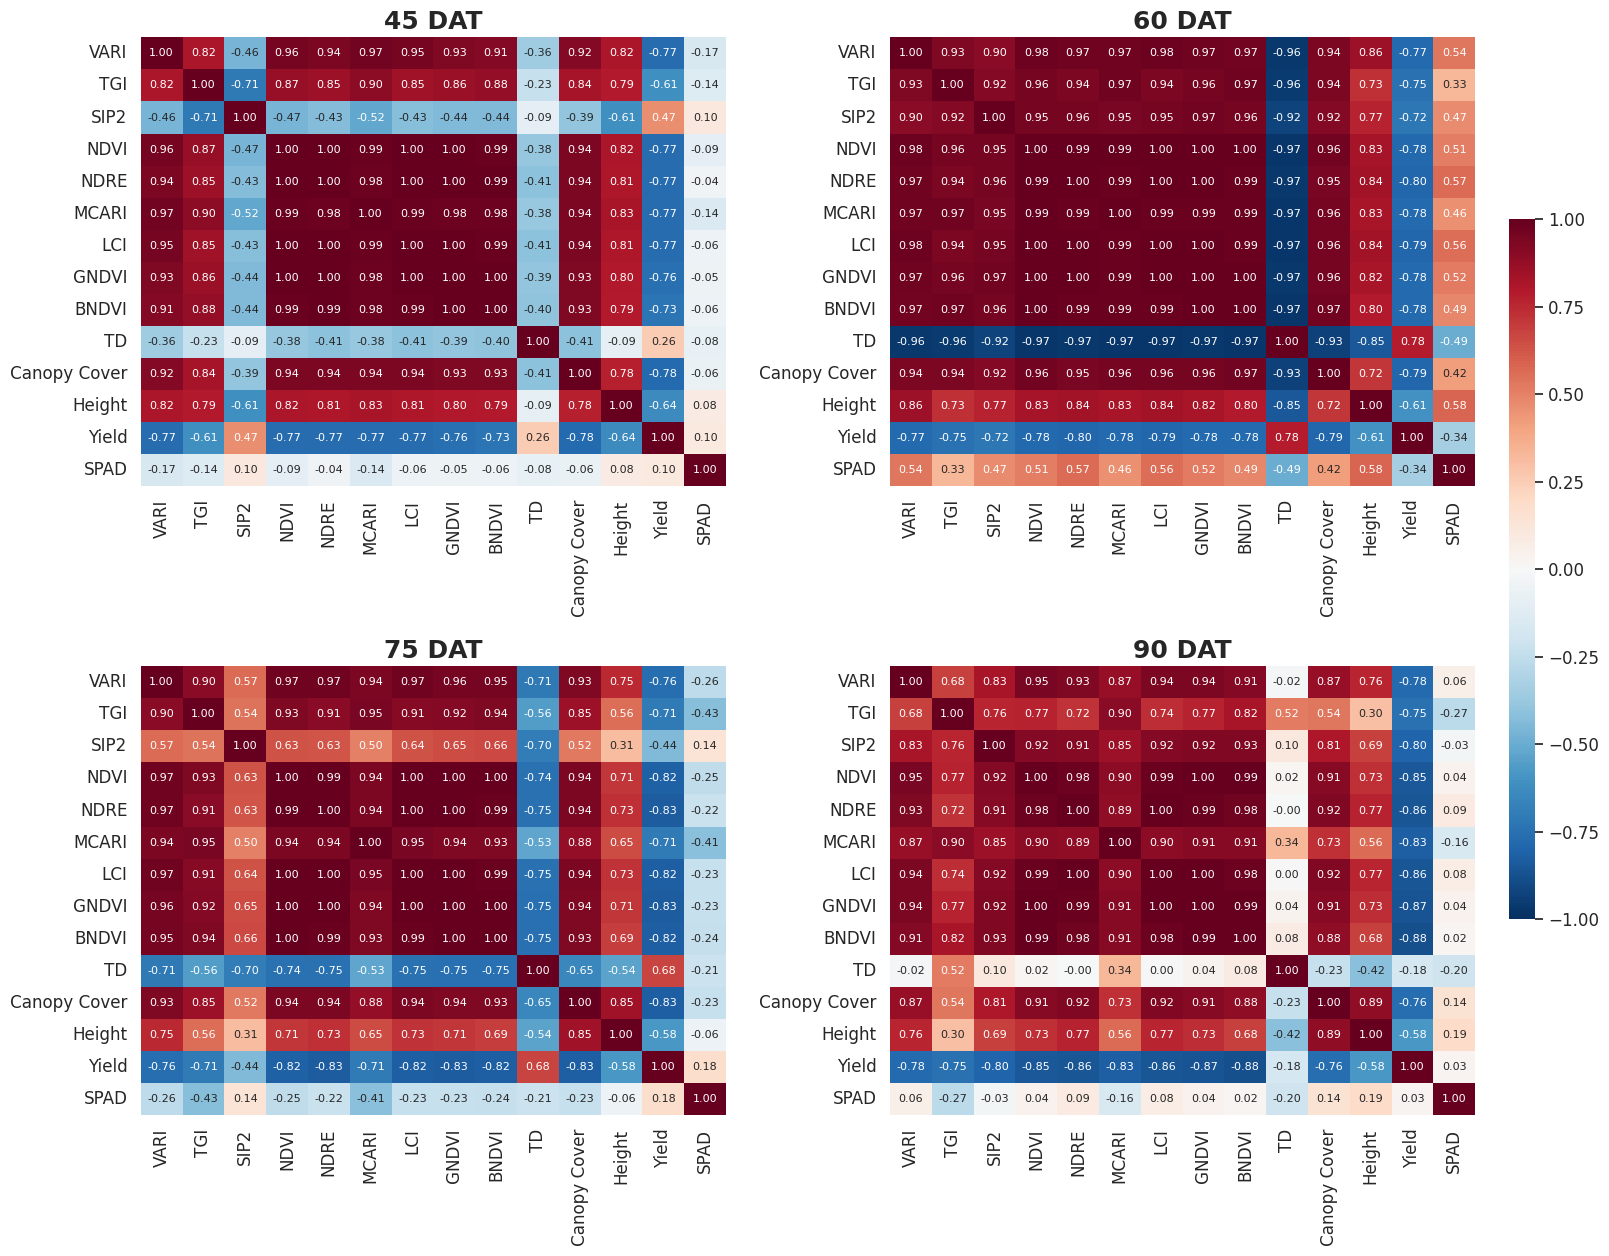

saved Fig3_correlation_matrices.png


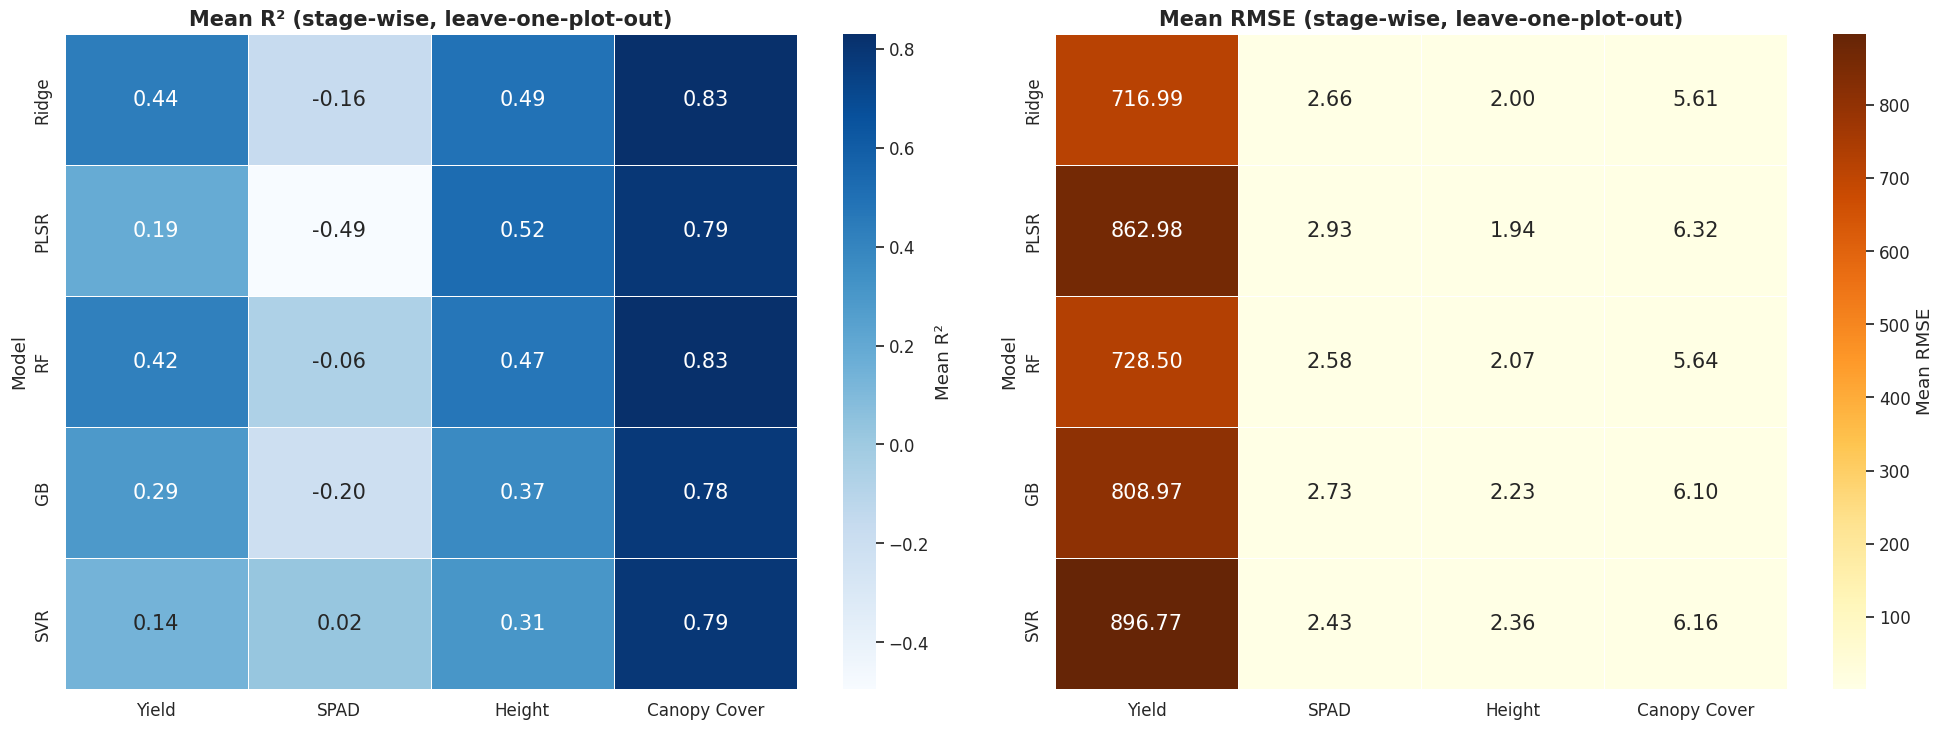

saved Fig4_model_performance_heatmaps.png


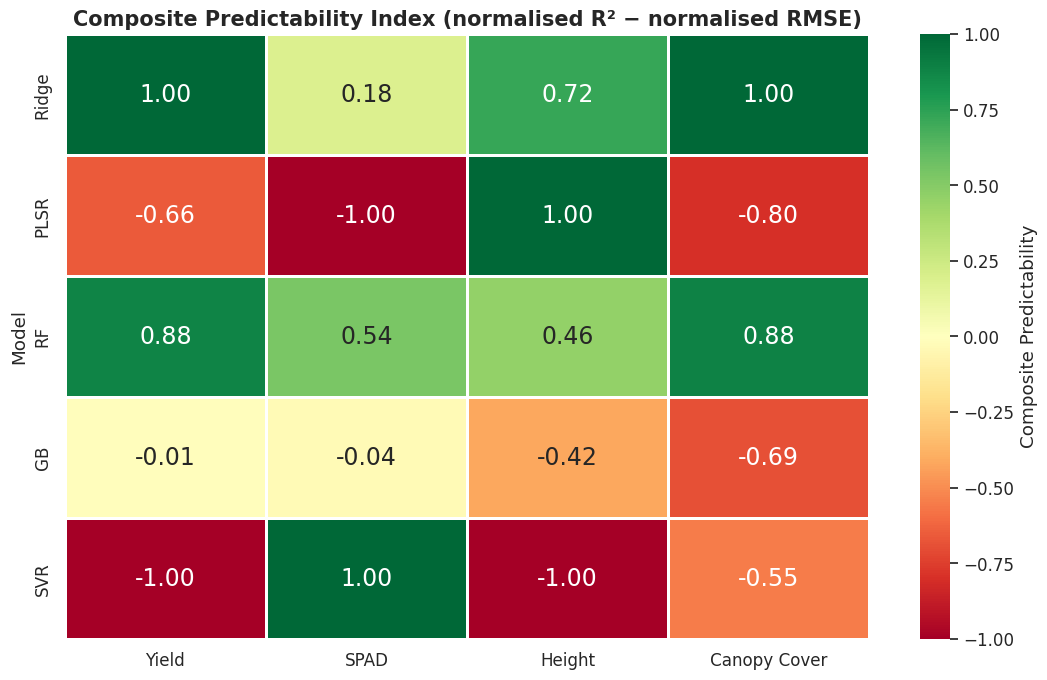

saved Fig5_composite_index.png


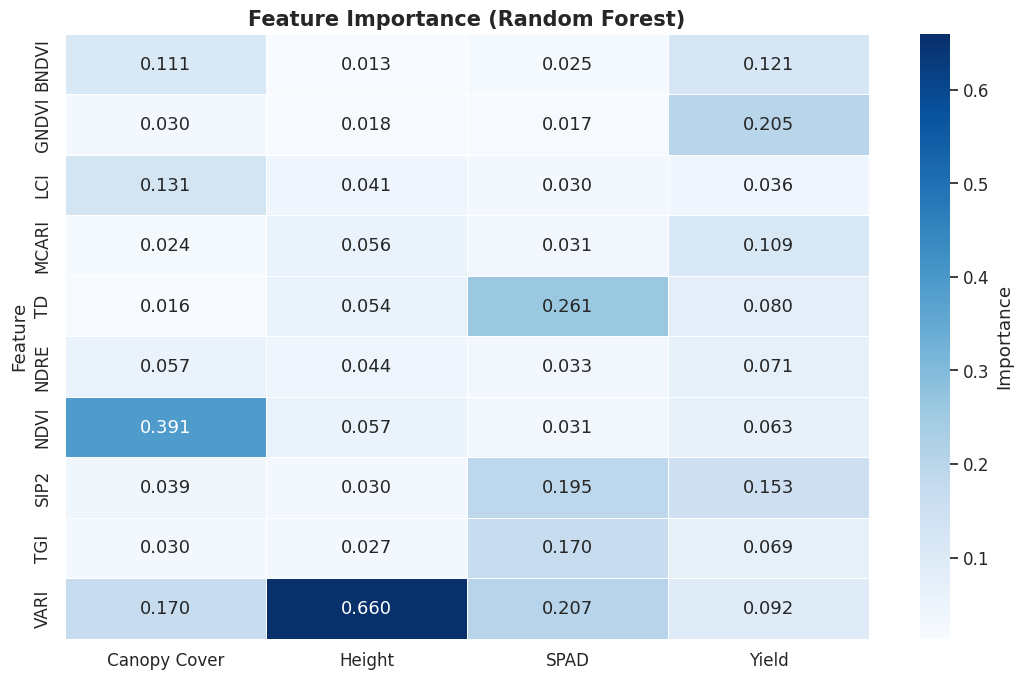

saved Fig6_importance_RF.png


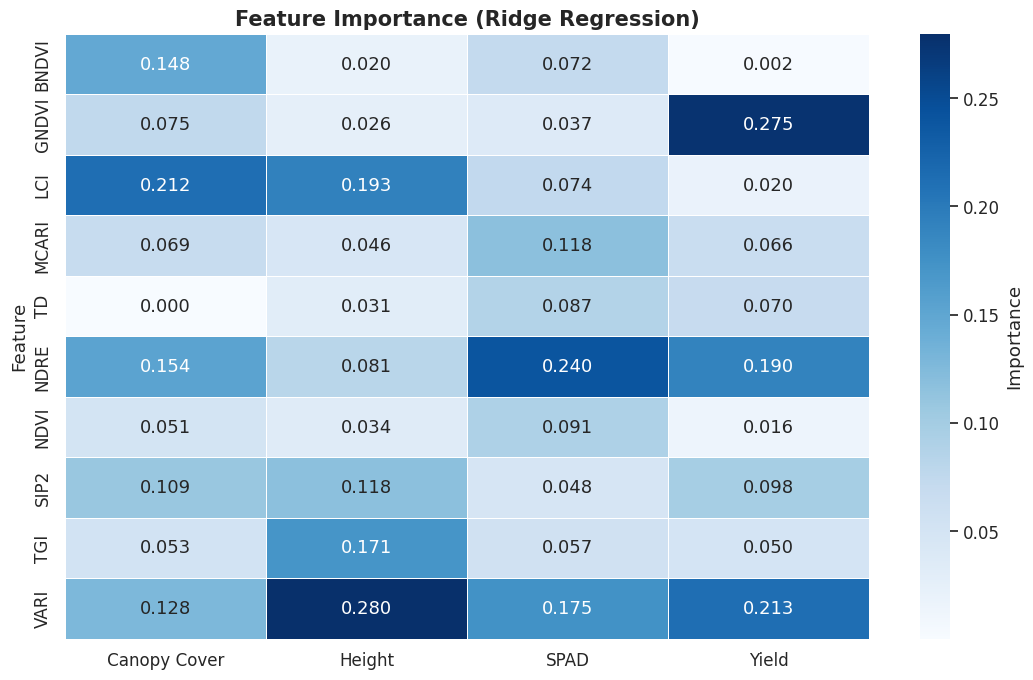

saved Fig7_importance_Ridge.png


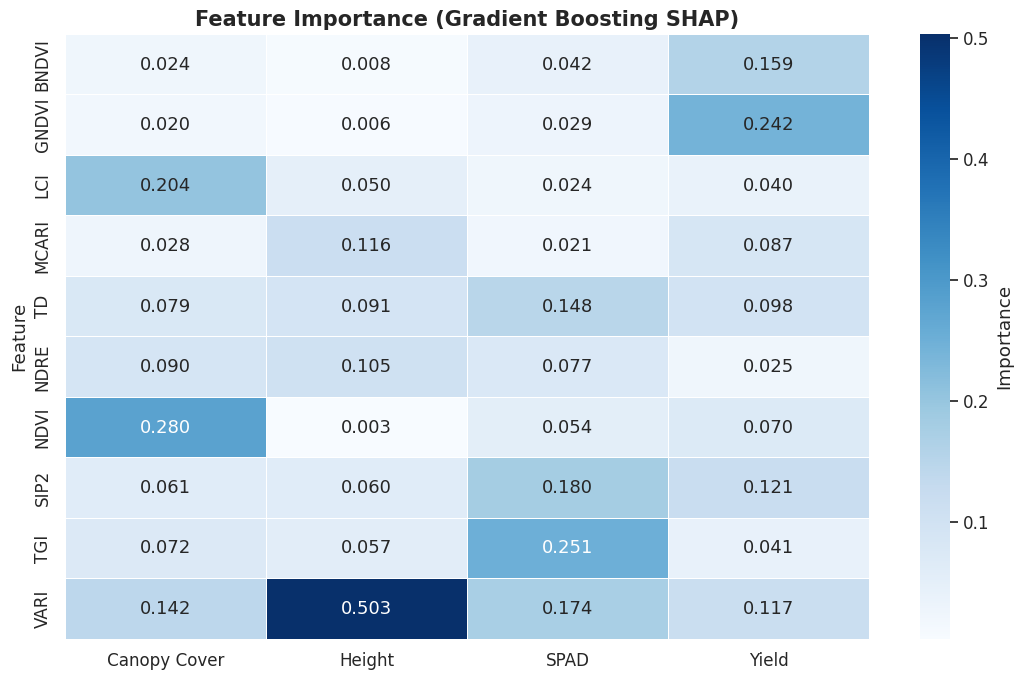

saved Fig8_importance_GB_SHAP.png


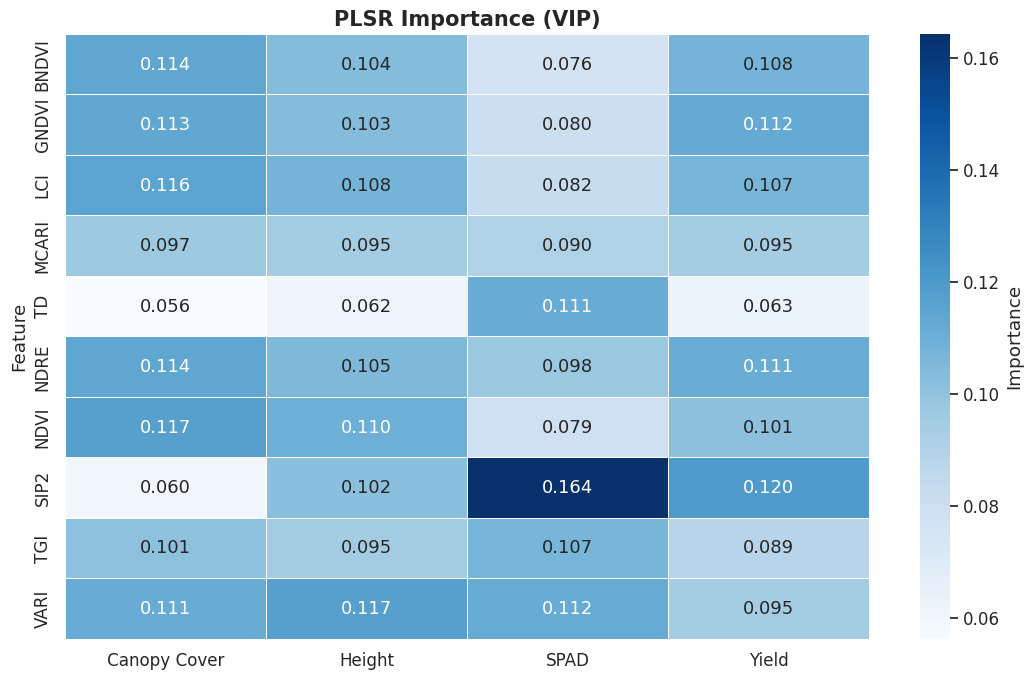

saved Fig9_importance_PLSR_VIP.png


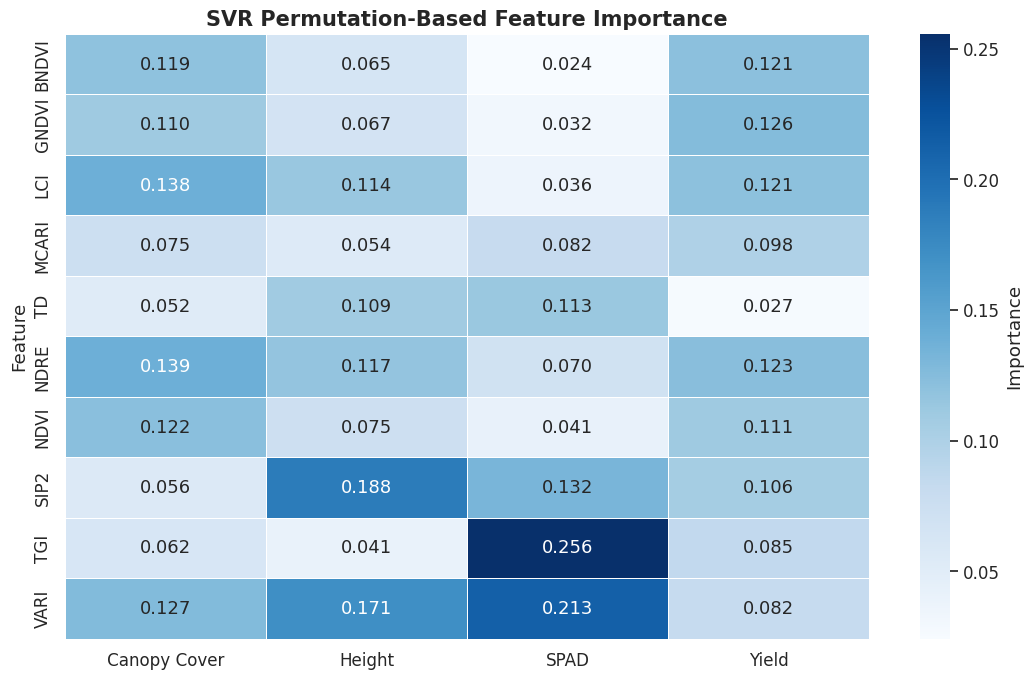

saved Fig10_importance_SVR_permutation.png


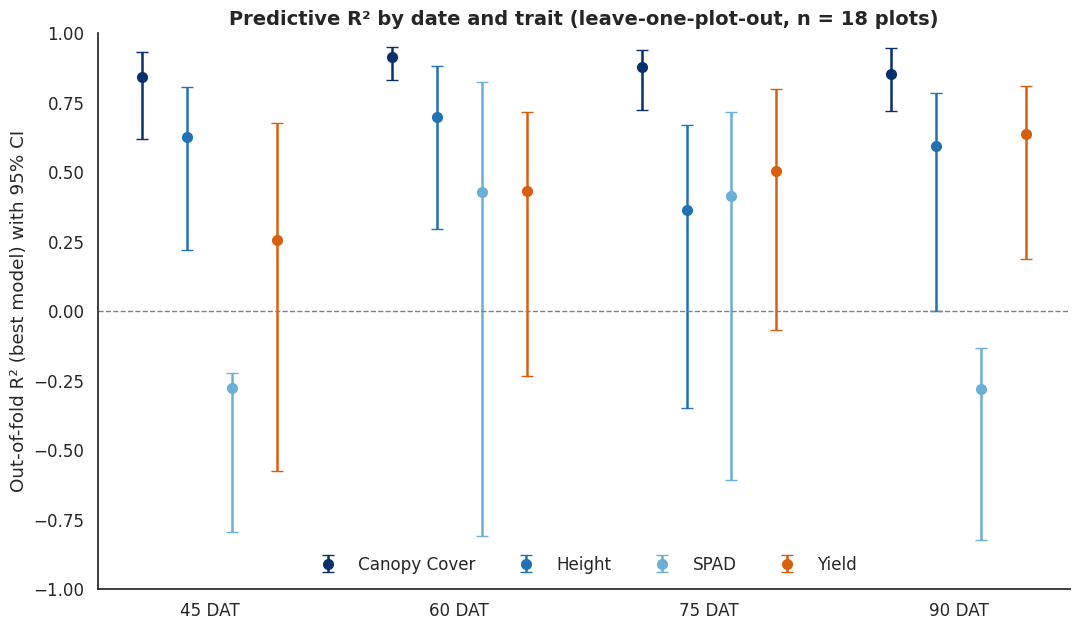

saved FigS1_R2_with_CI.png


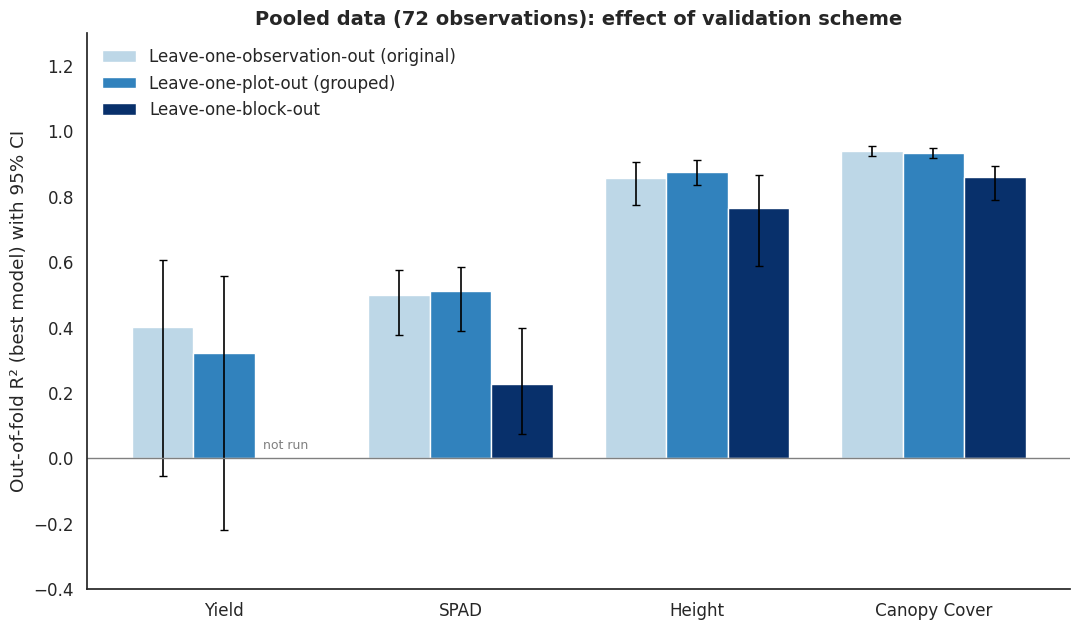

saved FigS2_validation_schemes.png

DONE. Figures made: Fig3_correlation_matrices.png, Fig4_model_performance_heatmaps.png, Fig5_composite_index.png, Fig6_importance_RF.png, Fig7_importance_Ridge.png, Fig8_importance_GB_SHAP.png, Fig9_importance_PLSR_VIP.png, Fig10_importance_SVR_permutation.png, FigS1_R2_with_CI.png, FigS2_validation_schemes.png
Folder: /content/revision_figures | zip: /content/revision_figures.zip


In [3]:

# =====================================================================
# HEMP UAV PHENOTYPING - MANUSCRIPT FIGURES
# Fig 3      Pearson correlation matrices (45, 60, 75, 90 DAT)
# Fig 4      Mean R2 and RMSE heatmaps (five models x four traits)
# Fig 5      Composite predictability index
# Figs 6-10  Feature importance: random forest, Ridge, gradient-boosting SHAP,
#            PLSR VIP, SVR permutation
# Fig S1     Best-model R2 with 95% CI by date and trait
# Fig S2     Pooled R2 under three validation schemes
#
# Input : Week1.xlsx - Week4.xlsx in /content (same files as the analysis cell)
# Output: 300 dpi PNG files in /content/revision_figures (and a .zip)
# Figs 3 and 6-10 are computed from the data. Figs 4, 5, S1 and S2 plot the
# model results from the final analysis run, which are embedded in this cell.
# =====================================================================
import subprocess, sys, importlib
for _p in ("shap", "seaborn"):
    try: importlib.import_module(_p)
    except Exception: subprocess.run([sys.executable, "-m", "pip", "-q", "install", _p], check=False)
import os, glob, zipfile, warnings
import numpy as np, pandas as pd
from pathlib import Path
warnings.filterwarnings("ignore")
import matplotlib
if "DISPLAY" not in os.environ and "COLAB_RELEASE_TAG" not in os.environ: matplotlib.use("Agg")
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.cross_decomposition import PLSRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

DATA_DIR = Path(os.environ.get("HEMP_DIR", "/content"))
OUT = Path(os.environ.get("HEMP_FIG_OUT", "/content/revision_figures")); OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
PRED = ["VARI","TGI","SIP2","NDVI","NDRE","MCARI","LCI","GNDVI","BNDVI","MEAN_TD"]
DATS = ["45 DAT","60 DAT","75 DAT","90 DAT"]
TRAITS_PUB = ["Yield","SPAD","Height","Canopy Cover"]          # order used in your Figs 4 and 5
REN = {"Yield (kg per ha)":"Yield","Yield kg per ha":"Yield","Mean_Height":"Height","Mean_SPAD":"SPAD",
       "Mean_Canopy Cover":"Canopy Cover","Mean_Canopy_Cover":"Canopy Cover"}
sns.set_theme(style="white", font_scale=1.1)
log = []
def save(fig, name):
    p = OUT / name; fig.savefig(p, dpi=300, bbox_inches="tight"); log.append(name)
    try: plt.show()
    except Exception: pass
    plt.close(fig); print("saved", name, flush=True)

# ---------------- data (same corrections as the analysis cell) ----------------
def find(i):
    h = sorted(glob.glob(str(DATA_DIR / f"*Week{i}*.xlsx")))
    if not h: raise FileNotFoundError(f"Upload Week{i}.xlsx to {DATA_DIR}")
    return h[0]
parts = []
for i, dat in enumerate(DATS, 1):
    d = pd.read_excel(find(i)).rename(columns=REN); d.columns = [str(c).strip() for c in d.columns]
    d["Plot"] = np.arange(1, len(d) + 1); d["DAT"] = dat; parts.append(d)
data = pd.concat(parts, ignore_index=True)
miss = [c for c in PRED + TRAITS_PUB if c not in data.columns]
assert not miss, f"Missing columns: {miss}. Found: {list(data.columns)}"
m1 = (data.DAT == "75 DAT") & (data.Plot == 10)
if abs(float(data.loc[m1, "Height"].iloc[0]) - 98.2) < 0.5: data.loc[m1, "Height"] = 34.48; print("CORRECTED plot 10 Height at 75 DAT")
m2 = (data.DAT == "60 DAT") & (data.Plot == 4)
if abs(float(data.loc[m2, "Canopy Cover"].iloc[0]) - 69.798) < 0.5: data.loc[m2, "Canopy Cover"] = 84.9; print("CORRECTED plot 4 Canopy Cover at 60 DAT")
print("Check:", float(data.loc[m1,"Height"].iloc[0]), float(data.loc[m2,"Canopy Cover"].iloc[0]), flush=True)

# ---------------- FIG 3: correlation matrices (corrected data; SR and NDWI are not in the files) ----------------
try:
    cols = PRED + ["Canopy Cover","Height","Yield","SPAD"]
    lab = {"MEAN_TD": "TD"}
    fig, axs = plt.subplots(2, 2, figsize=(17, 14))
    cbar_ax = fig.add_axes([0.93, 0.25, 0.015, 0.5])
    for k, (ax, dat) in enumerate(zip(axs.ravel(), DATS)):
        CM = data[data.DAT == dat][cols].corr()
        CM.index = [lab.get(c, c) for c in CM.index]; CM.columns = [lab.get(c, c) for c in CM.columns]
        sns.heatmap(CM, ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8},
                    cbar=(k == 0), cbar_ax=(cbar_ax if k == 0 else None), linewidths=0)
        ax.set_title(dat, fontsize=18, fontweight="bold")
    fig.subplots_adjust(right=0.91, hspace=0.40, wspace=0.28)
    save(fig, "Fig3_correlation_matrices.png")
except Exception as e: print("FIG 3 FAILED:", repr(e)[:300])

# ---------------- embedded final-run numbers (from your printout) ----------------
COMP = pd.DataFrame([  # Trait, Model, mean R2, mean RMSE, composite (stage-wise, 4 dates)
 ("Canopy Cover","GB",0.779,6.100,-0.694),("Canopy Cover","PLSR",0.789,6.315,-0.804),("Canopy Cover","RF",0.826,5.643,0.884),
 ("Canopy Cover","Ridge",0.830,5.611,1.000),("Canopy Cover","SVR",0.791,6.161,-0.548),
 ("Height","GB",0.371,2.235,-0.418),("Height","PLSR",0.522,1.942,1.000),("Height","RF",0.470,2.067,0.456),
 ("Height","Ridge",0.493,2.001,0.723),("Height","SVR",0.312,2.361,-1.000),
 ("SPAD","GB",-0.205,2.728,-0.037),("SPAD","PLSR",-0.494,2.933,-1.000),("SPAD","RF",-0.064,2.576,0.537),
 ("SPAD","Ridge",-0.164,2.658,0.181),("SPAD","SVR",0.024,2.428,1.000),
 ("Yield","GB",0.291,808.974,-0.008),("Yield","PLSR",0.186,862.976,-0.657),("Yield","RF",0.422,728.498,0.878),
 ("Yield","Ridge",0.440,716.994,1.000),("Yield","SVR",0.140,896.775,-1.000)],
 columns=["Trait","Model","R2","RMSE","Comp"])
MODELS = ["Ridge","PLSR","RF","GB","SVR"]
def mat(col): return COMP.pivot(index="Model", columns="Trait", values=col).loc[MODELS, TRAITS_PUB]

# ---------------- FIG 4: mean R2 and mean RMSE heatmaps ----------------
try:
    fig, axs = plt.subplots(1, 2, figsize=(20, 7.5))
    sns.heatmap(mat("R2"), ax=axs[0], annot=True, fmt=".2f", cmap="Blues", linewidths=0.5, linecolor="white",
                cbar_kws={"label": "Mean R²"}, annot_kws={"size": 15})
    sns.heatmap(mat("RMSE"), ax=axs[1], annot=True, fmt=".2f", cmap="YlOrBr", linewidths=0.5, linecolor="white",
                cbar_kws={"label": "Mean RMSE"}, annot_kws={"size": 15})
    for ax, t in zip(axs, ["Mean R² (stage-wise, leave-one-plot-out)", "Mean RMSE (stage-wise, leave-one-plot-out)"]):
        ax.set_title(t, fontsize=15, fontweight="bold"); ax.set_ylabel("Model"); ax.set_xlabel("")
    fig.tight_layout(); save(fig, "Fig4_model_performance_heatmaps.png")
except Exception as e: print("FIG 4 FAILED:", repr(e)[:300])

# ---------------- FIG 5: composite predictability index ----------------
try:
    fig, ax = plt.subplots(figsize=(11, 7))
    sns.heatmap(mat("Comp"), ax=ax, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1, linewidths=1, linecolor="white",
                cbar_kws={"label": "Composite Predictability"}, annot_kws={"size": 17})
    ax.set_title("Composite Predictability Index (normalised R² − normalised RMSE)", fontsize=15, fontweight="bold")
    ax.set_ylabel("Model"); ax.set_xlabel(""); fig.tight_layout(); save(fig, "Fig5_composite_index.png")
except Exception as e: print("FIG 5 FAILED:", repr(e)[:300])

# ---------------- FIGS 6-10: feature importance (same functions and settings as the analysis cell) ----------------
try:
    import shap
    def vip_scores(pls):
        T, W, Q = pls.x_scores_, pls.x_weights_, pls.y_loadings_
        p_, h = W.shape; s = np.diag(T.T @ T @ Q.T @ Q).reshape(h, -1)
        return np.sqrt(p_ * (W ** 2 @ s) / (s.sum() + 1e-12)).ravel()
    nrm = lambda v: np.asarray(v, float) / np.abs(v).sum()
    def importances(X, y, rf_trees=500, n_rep=20):
        Xv = X.values; Xs = StandardScaler().fit_transform(Xv); o = {}
        o["RF Gini"] = RandomForestRegressor(n_estimators=rf_trees, random_state=SEED, n_jobs=-1).fit(Xv, y).feature_importances_
        o["Ridge |coef|"] = nrm(np.abs(Ridge(alpha=1.0).fit(Xs, y).coef_))
        gb = GradientBoostingRegressor(random_state=SEED).fit(Xv, y)
        o["GB SHAP"] = nrm(np.abs(np.array(shap.TreeExplainer(gb).shap_values(Xv))).mean(0))
        o["PLSR VIP"] = nrm(vip_scores(PLSRegression(n_components=5).fit(Xs, y.reshape(-1, 1))))
        sv = Pipeline([("s", StandardScaler()), ("m", SVR(kernel="rbf", C=10, epsilon=0.1))]).fit(Xv, y)
        o["SVR permutation"] = nrm(permutation_importance(sv, Xv, y, n_repeats=n_rep, random_state=SEED, scoring="r2").importances_mean)
        return o
    IMP = {t: importances(data[PRED], data[t].values) for t in TRAITS_PUB}
    pd.DataFrame({(t, m): v for t, d_ in IMP.items() for m, v in d_.items()}, index=PRED).to_csv(OUT / "importance_point_estimates.csv")
    TITLES = {"RF Gini": ("Fig6_importance_RF.png", "Feature Importance (Random Forest)", "Importance"),
              "Ridge |coef|": ("Fig7_importance_Ridge.png", "Feature Importance (Ridge Regression)", "Importance"),
              "GB SHAP": ("Fig8_importance_GB_SHAP.png", "Feature Importance (Gradient Boosting SHAP)", "Importance"),
              "PLSR VIP": ("Fig9_importance_PLSR_VIP.png", "PLSR Importance (VIP)", "Importance"),
              "SVR permutation": ("Fig10_importance_SVR_permutation.png", "SVR Permutation-Based Feature Importance", "Importance")}
    order = ["Canopy Cover","Height","SPAD","Yield"]
    for m, (fn, ttl, cb) in TITLES.items():
        M = pd.DataFrame({t: IMP[t][m] for t in order}, index=PRED).sort_index()
        M.index = [("TD" if i == "MEAN_TD" else i) for i in M.index]
        fig, ax = plt.subplots(figsize=(11, 7))
        sns.heatmap(M, ax=ax, annot=True, fmt=".3f", cmap="Blues", linewidths=0.5, linecolor="white",
                    cbar_kws={"label": cb}, annot_kws={"size": 13})
        ax.set_title(ttl, fontsize=15, fontweight="bold"); ax.set_ylabel("Feature"); ax.set_xlabel("")
        fig.tight_layout(); save(fig, fn)
except Exception as e: print("FIGS 6-10 FAILED:", repr(e)[:300])

# ---------------- FIG S1: best-model R2 with 95% CI per date and trait ----------------
try:
    B = pd.DataFrame([  # DAT, Trait, R2, low, high  (best model per cell, cluster bootstrap by plot)
     ("45 DAT","Canopy Cover",0.840,0.619,0.932),("45 DAT","Height",0.626,0.219,0.807),("45 DAT","SPAD",-0.279,-0.796,-0.225),("45 DAT","Yield",0.255,-0.575,0.675),
     ("60 DAT","Canopy Cover",0.913,0.829,0.950),("60 DAT","Height",0.699,0.294,0.882),("60 DAT","SPAD",0.428,-0.809,0.825),("60 DAT","Yield",0.431,-0.234,0.714),
     ("75 DAT","Canopy Cover",0.877,0.723,0.940),("75 DAT","Height",0.362,-0.351,0.667),("75 DAT","SPAD",0.415,-0.608,0.714),("75 DAT","Yield",0.505,-0.070,0.797),
     ("90 DAT","Canopy Cover",0.851,0.720,0.945),("90 DAT","Height",0.594,-0.000,0.783),("90 DAT","SPAD",-0.280,-0.825,-0.132),("90 DAT","Yield",0.636,0.188,0.809)],
     columns=["DAT","Trait","R2","lo","hi"])
    pal = {"Canopy Cover": "#08306b", "Height": "#2171b5", "SPAD": "#6baed6", "Yield": "#d95f0e"}
    fig, ax = plt.subplots(figsize=(11, 6.5)); w = 0.18
    for k, t in enumerate(["Canopy Cover","Height","SPAD","Yield"]):
        s = B[B.Trait == t]; x = np.arange(4) + (k - 1.5) * w
        ax.errorbar(x, s.R2, yerr=[s.R2 - s.lo, s.hi - s.R2], fmt="o", color=pal[t], capsize=4, lw=1.8, ms=7, label=t)
    ax.axhline(0, color="grey", lw=1, ls="--"); ax.set_xticks(range(4)); ax.set_xticklabels(DATS)
    ax.set_ylabel("Out-of-fold R² (best model) with 95% CI"); ax.set_ylim(-1.0, 1.0)
    ax.set_title("Predictive R² by date and trait (leave-one-plot-out, n = 18 plots)", fontsize=14, fontweight="bold")
    ax.legend(ncol=4, loc="lower center", frameon=False); sns.despine(); fig.tight_layout(); save(fig, "FigS1_R2_with_CI.png")
except Exception as e: print("FIG S1 FAILED:", repr(e)[:300])

# ---------------- FIG S2: pooled data under three validation schemes ----------------
try:
    V = pd.DataFrame([  # scheme, trait, R2, lo, hi
     ("Leave-one-observation-out (original)","Canopy Cover",0.938,0.923,0.953),("Leave-one-observation-out (original)","Height",0.856,0.775,0.905),
     ("Leave-one-observation-out (original)","SPAD",0.500,0.376,0.576),("Leave-one-observation-out (original)","Yield",0.402,-0.055,0.606),
     ("Leave-one-plot-out (grouped)","Canopy Cover",0.934,0.918,0.948),("Leave-one-plot-out (grouped)","Height",0.875,0.835,0.910),
     ("Leave-one-plot-out (grouped)","SPAD",0.512,0.389,0.584),("Leave-one-plot-out (grouped)","Yield",0.320,-0.220,0.556),
     ("Leave-one-block-out","Canopy Cover",0.858,0.789,0.894),("Leave-one-block-out","Height",0.765,0.586,0.864),
     ("Leave-one-block-out","SPAD",0.226,0.072,0.398)], columns=["Scheme","Trait","R2","lo","hi"])
    cols3 = {"Leave-one-observation-out (original)": "#bdd7e7", "Leave-one-plot-out (grouped)": "#3182bd", "Leave-one-block-out": "#08306b"}
    fig, ax = plt.subplots(figsize=(11, 6.5)); w = 0.26
    for k, (sch, c) in enumerate(cols3.items()):
        s = V[V.Scheme == sch].set_index("Trait").reindex(TRAITS_PUB); x = np.arange(4) + (k - 1) * w
        ax.bar(x, s.R2.fillna(0), w, color=c, label=sch, edgecolor="white")
        ax.errorbar(x, s.R2, yerr=[s.R2 - s.lo, s.hi - s.R2], fmt="none", ecolor="black", capsize=3, lw=1.2)
    ax.axhline(0, color="grey", lw=1); ax.set_xticks(range(4)); ax.set_xticklabels(TRAITS_PUB)
    ax.set_ylabel("Out-of-fold R² (best model) with 95% CI"); ax.set_ylim(-0.4, 1.3)
    ax.set_title("Pooled data (72 observations): effect of validation scheme", fontsize=14, fontweight="bold")
    ax.text(0 + 1 * w, 0.03, "not run", ha="center", fontsize=9, color="grey")
    ax.legend(frameon=False, loc="upper left", ncol=1); sns.despine(); fig.tight_layout(); save(fig, "FigS2_validation_schemes.png")
except Exception as e: print("FIG S2 FAILED:", repr(e)[:300])

zp = str(OUT) + ".zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.glob("*")): z.write(f, f.name)
print("\nDONE. Figures made:", ", ".join(log)); print("Folder:", OUT, "| zip:", zp)

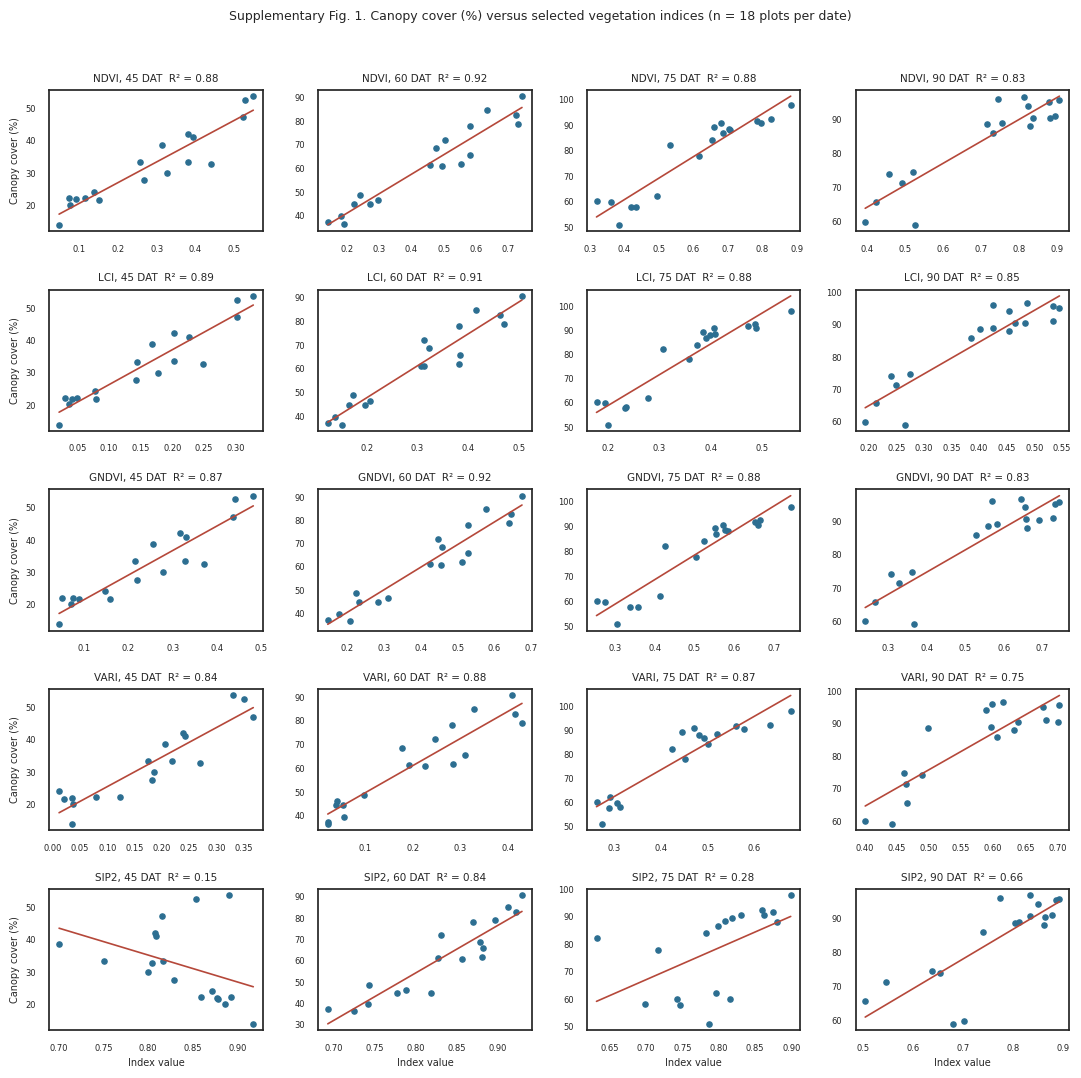

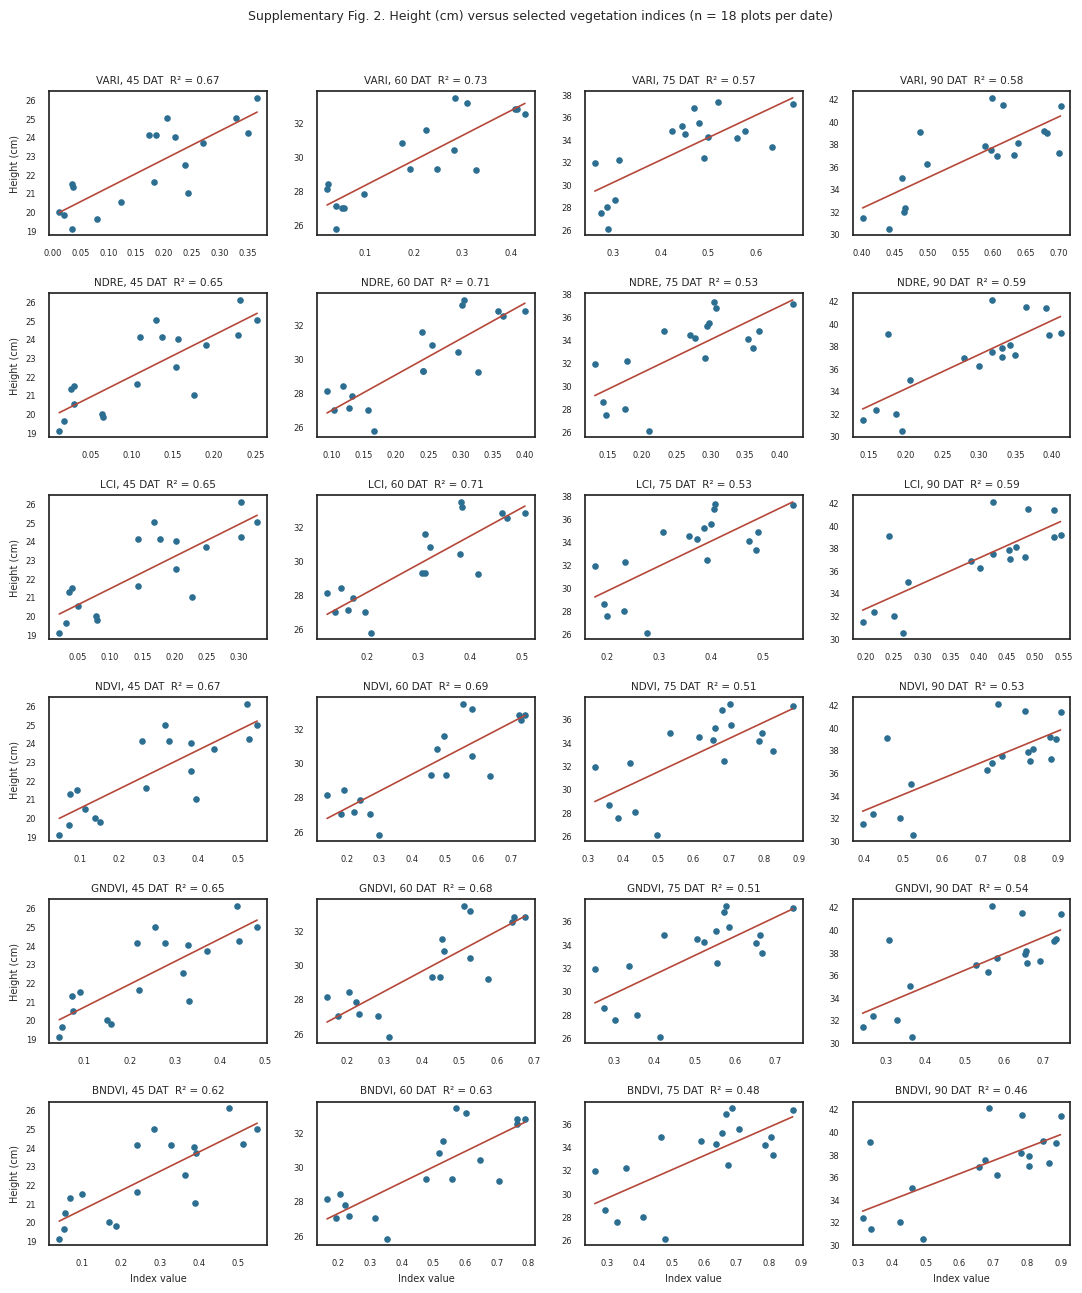

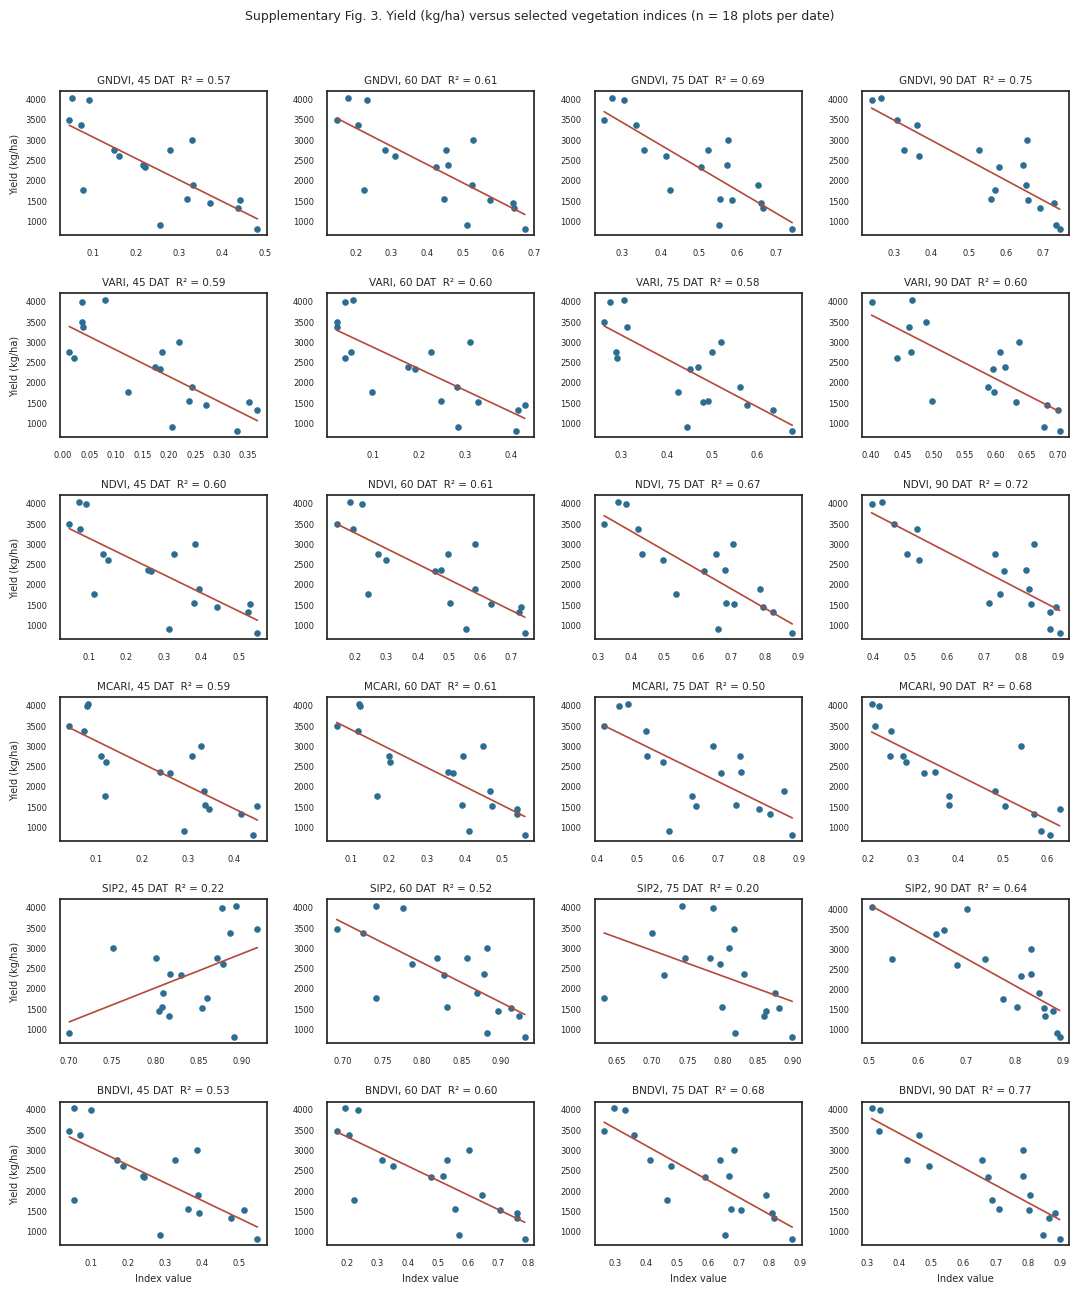

saved Supplementary Figs 1-3 to /content/revision_figures


In [4]:
# =====================================================================
# SUPPLEMENTARY FIGS 1-3
# Scatter plots with simple linear regression lines (R2 shown) of canopy cover,
# plant height and yield against selected vegetation indices at each date.
# Uses the data frame and output folder created by the figures cell.
# =====================================================================

import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
SEL = {"Canopy Cover": ["NDVI", "LCI", "GNDVI", "VARI", "SIP2"],
       "Height":       ["VARI", "NDRE", "LCI", "NDVI", "GNDVI", "BNDVI"],
       "Yield":        ["GNDVI", "VARI", "NDVI", "MCARI", "SIP2", "BNDVI"]}
UNITS = {"Canopy Cover": "Canopy cover (%)", "Height": "Height (cm)", "Yield": "Yield (kg/ha)"}
_out = OUT if "OUT" in globals() else Path(".")
for n, (trait, idxs) in enumerate(SEL.items(), 1):
    fig, ax = plt.subplots(len(idxs), 4, figsize=(11, 2.2 * len(idxs)), squeeze=False)
    for i, idx in enumerate(idxs):
        for j, d in enumerate(["45 DAT", "60 DAT", "75 DAT", "90 DAT"]):
            a = ax[i][j]; s = data[data.DAT == d]; x = s[idx].values; y = s[trait].values
            a.scatter(x, y, s=14, color="#2c6e91"); r = stats.linregress(x, y)
            xs = np.linspace(x.min(), x.max(), 20); a.plot(xs, r.intercept + r.slope * xs, color="#b5483a", lw=1.2)
            a.set_title(f"{idx}, {d}  R² = {r.rvalue**2:.2f}", fontsize=7.5); a.tick_params(labelsize=6)
            if j == 0: a.set_ylabel(UNITS[trait], fontsize=7)
            if i == len(idxs) - 1: a.set_xlabel("Index value", fontsize=7)
    fig.suptitle(f"Supplementary Fig. {n}. {UNITS[trait]} versus selected vegetation indices (n = 18 plots per date)", fontsize=9)
    fig.tight_layout(rect=(0, 0, 1, 0.97)); fig.savefig(_out / f"SuppFig{n}_{trait.replace(' ', '')}.png", dpi=200)
    plt.show(); plt.close(fig)
print("saved Supplementary Figs 1-3 to", _out)